# Client dropout: EDA and modelling

**Question:** which of my personal-training clients will stop training in the next 30 days - and what should I do about it?

As a coach, losing a client costs more than the fee: it's usually someone who didn't get the result they came for. If I can spot the risk early, a 10-minute call often fixes it.

This notebook walks through the data, the model comparison, the business threshold and the explanations. The same code runs in `src/dropout/` so the notebook and the production API can't drift apart.

> **Data note:** real client data is private, so the dataset is synthetic - generated from patterns I see in coaching (see `src/dropout/data.py`). The pipeline works unchanged on a real export with the same columns.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dropout.config import FEATURES, TARGET, NUMERIC_FEATURES
from dropout.data import generate_clients
from dropout.features import add_engineered_features
from dropout import plots
%matplotlib inline

pd.set_option("display.precision", 3)
BLUE, ORANGE, AQUA = plots.SERIES
df = pd.read_csv("../data/clients.csv")
print(f"{len(df):,} clients, {df.shape[1]} columns, dropout rate {df[TARGET].mean():.1%}")
df.head()

4,000 clients, 20 columns, dropout rate 25.5%


,client_id,age,gender,goal,plan_type,plan_months,monthly_fee_inr,tenure_weeks,referred,took_trial,sessions_planned_per_week,attendance_rate_4w,attendance_trend,days_since_last_workout,checkin_response_rate,avg_form_score,weight_progress_pct,paused_weeks_used,support_msgs_30d,dropped_out
0,C00001,33,M,fat_loss,in_person,3,6667,2,1,1,3,0.812,-0.039,1,0.416,NaN,57.5,0,2,0
1,C00002,38,F,fat_loss,in_person,3,6667,14,1,1,3,0.868,0.169,1,0.568,67.3,46.6,1,2,0
2,C00003,33,M,fat_loss,online,1,4000,20,0,0,5,0.919,0.186,1,0.912,74.5,95.1,1,5,0
3,C00004,49,M,muscle_gain,online,3,3333,1,0,0,5,0.862,0.147,1,0.883,83.7,60.6,0,6,0
4,C00005,42,M,general_fitness,online,3,3333,8,0,1,5,0.192,-0.073,0,0.266,NaN,10.4,1,0,1


## 1. Data quality

In [2]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_%": (df.isna().mean() * 100).round(1), "unique": df.nunique()})
quality[quality["missing_%"] > 0]

,dtype,missing_%,unique
checkin_response_rate,float64,6.0,863
avg_form_score,float64,31.4,525


Two columns have gaps, and they mean different things:

* `avg_form_score` is missing for ~30% of clients - they don't use the AI Rep Counter. **Missing here is information**, so I add a `uses_app` flag instead of only imputing.
* `checkin_response_rate` is missing for ~6% - clients who never got a check-in form. Median imputation inside the pipeline is enough.

## 2. What separates clients who leave from clients who stay?

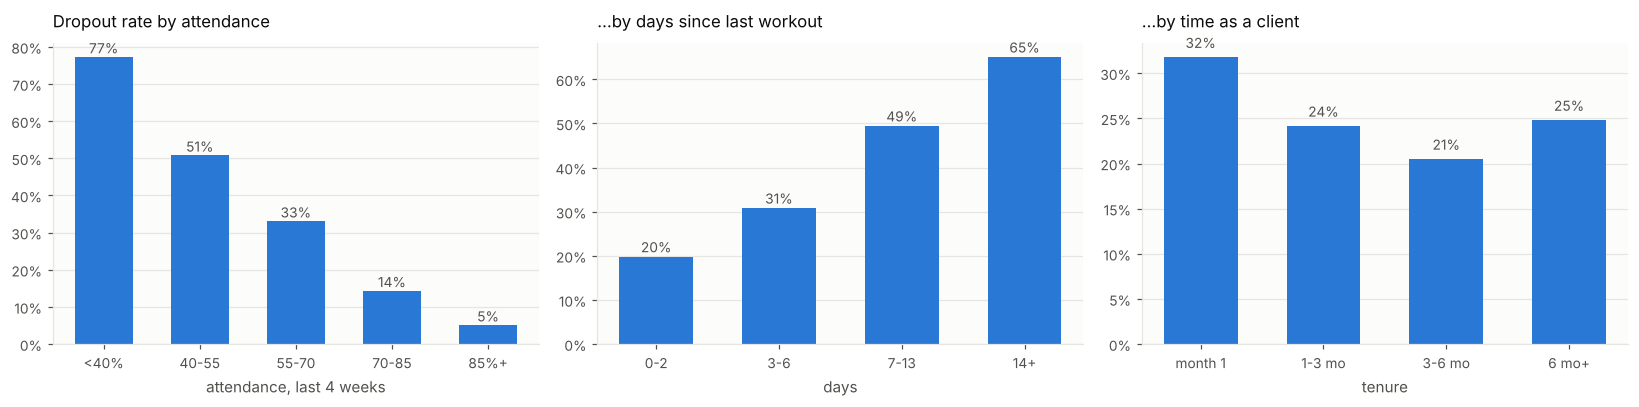

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), dpi=110)

def bar_rate(ax, series, title, xlabel):
    rate = df.groupby(series, observed=False)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
    for x, v in enumerate(rate.values):
        ax.text(x, v + 0.01, f"{v:.0%}", ha="center", fontsize=9, color=plots.INK_2)
    plots._style(ax, title)
    ax.set_xlabel(xlabel)
    ax.yaxis.set_major_formatter(plots.PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", visible=False)

bar_rate(axes[0], pd.cut(df["attendance_rate_4w"], [0, .4, .55, .7, .85, 1], labels=["<40%", "40-55", "55-70", "70-85", "85%+"]),
         "Dropout rate by attendance", "attendance, last 4 weeks")
bar_rate(axes[1], pd.cut(df["days_since_last_workout"], [-1, 2, 6, 13, 99], labels=["0-2", "3-6", "7-13", "14+"]),
         "...by days since last workout", "days")
bar_rate(axes[2], pd.cut(df["tenure_weeks"], [0, 4, 12, 26, 60], labels=["month 1", "1-3 mo", "3-6 mo", "6 mo+"]),
         "...by time as a client", "tenure")
fig.tight_layout()

Exactly what I see on the gym floor:

* **Attendance is the loudest signal.** Clients attending under 40% of planned sessions leave most of the time; at 85%+ almost nobody leaves.
* **Gaps compound.** After two weeks without a workout, about two in three clients leave.
* **Month one is the danger zone.** Dropout is highest in the first four weeks, then settles.

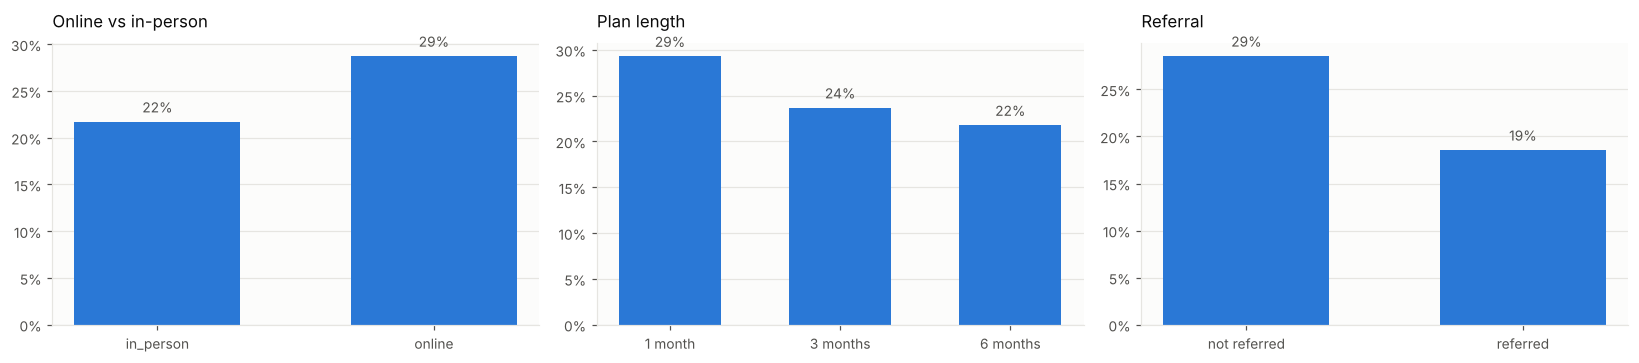

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), dpi=110)
bar_rate(axes[0], df["plan_type"], "Online vs in-person", "")
bar_rate(axes[1], df["plan_months"].map({1: "1 month", 3: "3 months", 6: "6 months"}), "Plan length", "")
bar_rate(axes[2], df["referred"].map({0: "not referred", 1: "referred"}), "Referral", "")
fig.tight_layout()

In-person, longer plans and referred clients are stickier - commitment and social proof both matter.

## 3. Feature engineering

Raw columns plus four features a coach would reason with (`src/dropout/features.py`):

| feature | idea |
|---|---|
| `fee_per_session_inr` | what each session "costs" the client - value perception |
| `is_new_client` | first 4 weeks flag (month-one risk) |
| `uses_app` | turns "missing form score" into a signal |
| `engagement_index` | 0.5 x attendance + 0.3 x check-in replies + 0.2 x recency (decays with days since last workout) |

The fill value for missing check-ins is a **fixed constant**, not the batch median, so one client scored by the API gets exactly the same feature as in training (no training/serving skew - there's a test for this).

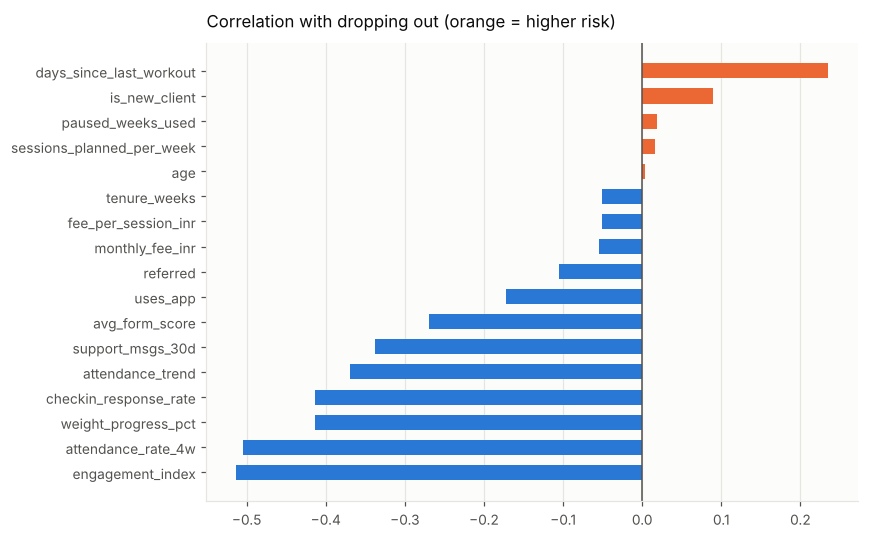

In [5]:
data = add_engineered_features(df)
corr = data[NUMERIC_FEATURES + ["uses_app", "is_new_client", "referred"] + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
ax.barh(corr.index, corr.values, color=[ORANGE if v > 0 else BLUE for v in corr.values], height=0.6)
plots._style(ax, "Correlation with dropping out (orange = higher risk)")
ax.axvline(0, color=plots.INK_2, lw=1)
ax.grid(axis="y", visible=False)
fig.tight_layout()

## 4. Model comparison

Three models, from simple to flexible, compared with **5-fold stratified cross-validation on the training set only**. The 20% test set is touched once, at the very end.

Every model sits inside a scikit-learn `Pipeline` (impute -> scale -> one-hot -> model), so imputation medians and scaling are learned on training folds only - no leakage.

In [6]:
from dropout.train import train
bundle = train(df, make_figures=False, verbose=False)
m = bundle["metrics"]
cv = pd.DataFrame(m["cross_validation"]).T[["roc_auc", "pr_auc", "brier", "threshold", "precision", "recall", "savings_per_100_clients_inr"]]
cv.sort_values("savings_per_100_clients_inr", ascending=False)

,roc_auc,pr_auc,brier,threshold,precision,recall,savings_per_100_clients_inr
logistic_regression,0.854,0.695,0.126,0.16,0.467,0.869,46109.375
random_forest,0.845,0.683,0.128,0.17,0.452,0.853,44532.812
gradient_boosting,0.837,0.668,0.135,0.14,0.462,0.821,43332.812


**The simplest model wins.** Logistic regression matches or beats the tree ensembles on ROC-AUC, PR-AUC and money saved. The signal here is mostly additive ("lower attendance -> higher risk"), which is exactly what a linear model captures - the extra flexibility of the ensembles mostly fits noise on 3,200 rows.

I ship the logistic regression: same accuracy, faster, and every coefficient can be explained to a non-technical coach. *Always run the baseline first.*

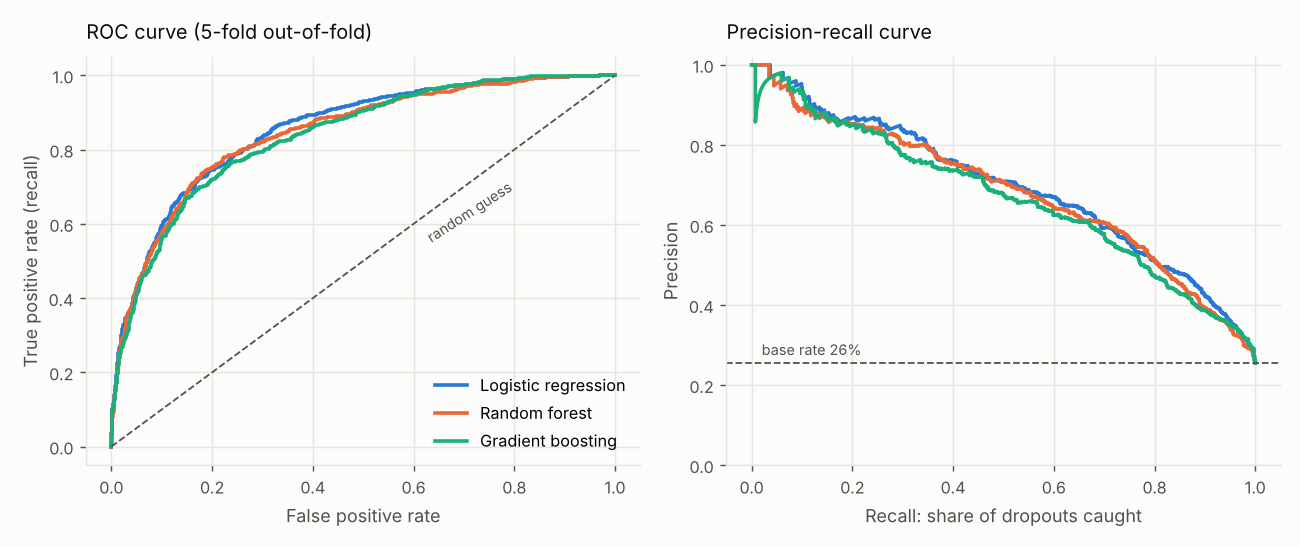

In [7]:
from IPython.display import Image
Image("../reports/figures/model_comparison.png")

## 5. Choosing the threshold with money, not 0.5

A flagged client gets a call + one free session. Assumptions (`src/dropout/config.py`):

* a dropout costs ~**Rs 9,000** of future fees,
* a retention action costs ~**Rs 500**,
* a good call keeps ~**35%** of truly at-risk clients.

So catching a real dropout is worth 0.35 x 9,000 - 500 = **Rs 2,650**, and a false alarm costs **Rs 500**. Missing a dropout is far more expensive than an unnecessary call, so the best threshold sits well below 0.5. I pick it on **out-of-fold** predictions so the test set stays untouched.

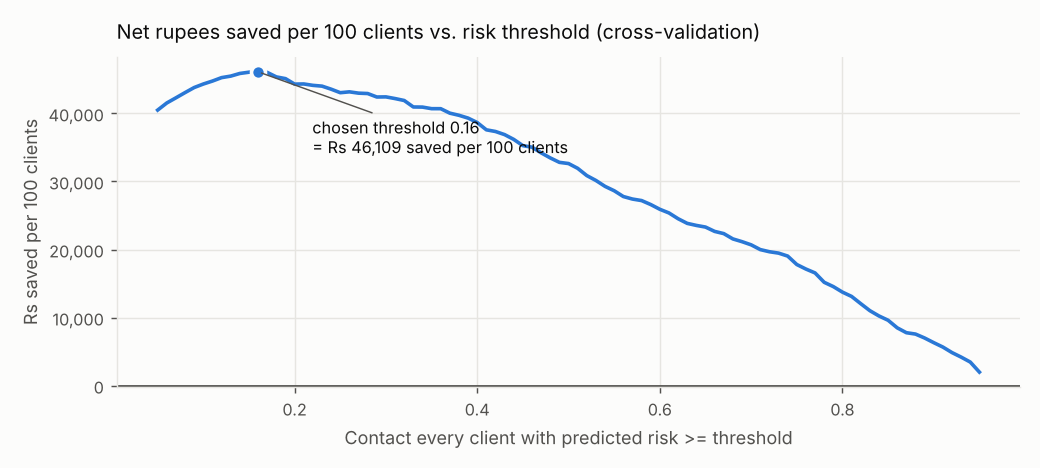

In [8]:
Image("../reports/figures/savings_vs_threshold.png")

## 6. Final evaluation on the held-out test set

Model: logistic_regression, threshold 0.16
roc_auc                           0.828
pr_auc                            0.646
brier                             0.138
precision                         0.433
recall                            0.833
flagged_share                     0.491
savings_inr                    339000.0
savings_per_100_clients_inr     42375.0


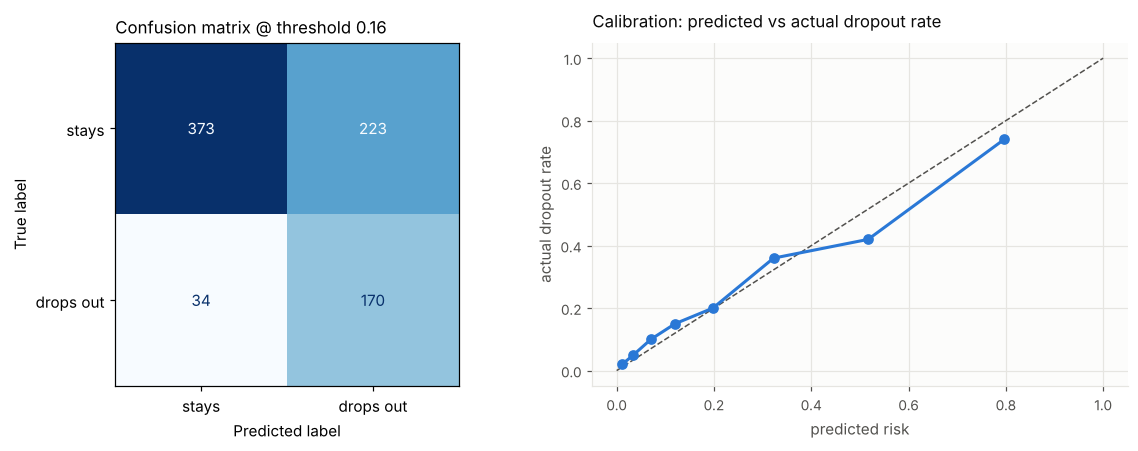

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split

X, y = data[FEATURES], data[TARGET]
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
proba = bundle["pipeline"].predict_proba(X_test)[:, 1]
thr = bundle["threshold"]

print(f"Model: {bundle['model_name']}, threshold {thr:.2f}")
print(pd.Series(m["test"]).drop("confusion_matrix").round(3).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=110)
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= thr).astype(int), display_labels=["stays", "drops out"],
                                        cmap="Blues", colorbar=False, ax=ax1)
ax1.set_title(f"Confusion matrix @ threshold {thr:.2f}", loc="left", fontsize=11)
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=8, strategy="quantile")
ax2.plot([0, 1], [0, 1], color=plots.INK_2, ls="--", lw=1)
ax2.plot(mean_pred, frac_pos, color=BLUE, lw=2, marker="o", ms=6)
plots._style(ax2, "Calibration: predicted vs actual dropout rate")
ax2.set(xlabel="predicted risk", ylabel="actual dropout rate")
fig.tight_layout()

* The model catches most dropouts (high recall) at the cost of extra calls - the right trade given the costs above.
* **Calibration is close to the diagonal**, so a predicted 30% really means ~30%. That's why I didn't use `class_weight="balanced"` (it inflates probabilities); I handle the 25% minority class with the threshold instead.

## 7. Why is a client at risk? (SHAP)

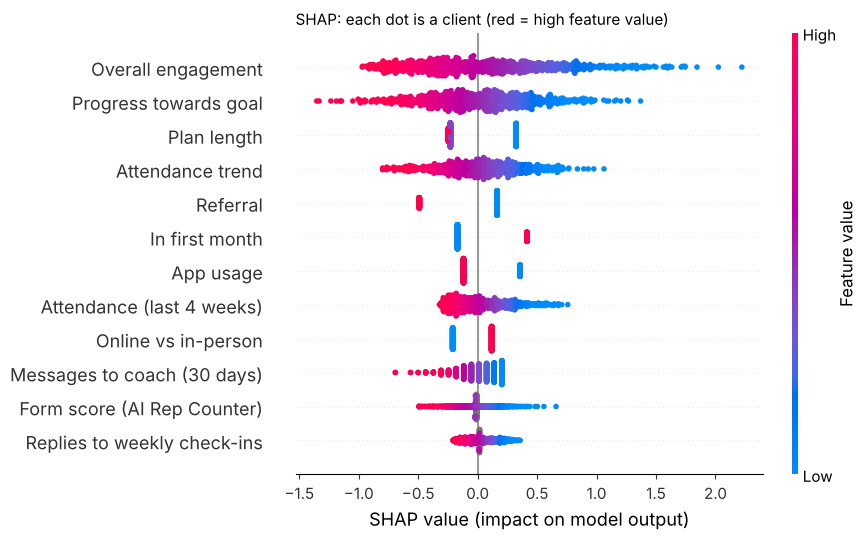

In [10]:
import shap
from dropout.explain import Explainer, READABLE

explainer = Explainer(bundle["pipeline"], bundle["background"])
contrib = explainer.shap_by_feature(X_test)
display_X = X_test[contrib.columns].copy()
for col in display_X.select_dtypes("object"):
    display_X[col] = display_X[col].astype("category").cat.codes
shap.summary_plot(contrib.values, display_X.astype(float), feature_names=[READABLE.get(c, c) for c in contrib.columns],
                  max_display=12, show=False, plot_size=(9, 5.5))
plt.title("SHAP: each dot is a client (red = high feature value)", loc="left", fontsize=11)
plt.tight_layout()

Low attendance, a falling attendance trend, long gaps since the last workout and slow progress push risk up; referrals, in-person training and longer plans pull it down.

Now one specific client - this is what the API returns:

In [11]:
from dropout.explain import suggested_actions
idx = proba.argmax()
row = X_test.iloc[[idx]]
reasons = explainer.top_reasons(row, k=3)[0]
print(f"Client {df.loc[row.index[0], 'client_id']}: predicted risk {proba[idx]:.0%}\n")
for r in reasons:
    print(f"  + {r['label']:<32} value={r['value']!s:<8} impact={r['impact']:+.2f}")
print("\nSuggested actions:")
for a in suggested_actions(reasons):
    print("  -", a)

Client C01306: predicted risk 98%

  + Overall engagement               value=0.328    impact=+1.33
  + Progress towards goal            value=-3.7     impact=+1.27
  + Attendance trend                 value=-0.462   impact=+0.89

Suggested actions:
  - Re-engage: short call, a fresh weekly target, celebrate a small win.
  - Review the plan together and set a small 2-week goal they can hit.


## 8. Takeaways & next steps

* A simple, well-validated logistic regression matched more complex models - and is easier to trust and explain.
* Choosing the threshold from business costs turns "ROC-AUC 0.83" into "**~Rs 42,000 saved per 100 clients**" (test set). The cost-optimal threshold (0.16) landed right on the break-even probability 500 / (0.35 x 9,000) = 0.16 - a nice sanity check that the probabilities are calibrated.
* SHAP turns a score into a reason and a next step a coach can act on today.

**Next:**
1. Replace synthetic data with my real client history (same schema) and re-validate.
2. Feed `avg_form_score` and `days_since_last_workout` automatically from the [AI Rep Counter](https://github.com/coach-who-codes/ai-rep-counter) workout log (`features.aggregate_workout_log`).
3. Add a capacity limit ("I can make 10 calls a week") - rank by expected savings instead of a fixed threshold.
4. Track model drift monthly; retrain when the dropout rate or feature distributions shift.